# Part 3 — Customer Churn Prediction with Artificial Neural Networks (ANN)

**ACS Work Integrated Learning — Team 8**  
**Prepared by:** Bao Ngoc Nguyen — Data Analyst (Predictive Modelling)  
**Input:** *OLD + NEW* Stage 2 customer datasets (7,043 and 6,741 records), starting from the *NEW* cleaned customer dataset (**6,741 rows, after removal of 302 exact duplicates**) and its companion file with customer segments.  
**Purpose:** Develop, evaluate and explain customer-level churn prediction using a 70/20/10 grouped holdout; assess whether adding K-Means cluster labels improves ANN performance, and quantify the effect of retaining vs removing 302 exact duplicate rows on the *same independent test customers*.

### How this notebook is structured
Each section follows the explanatory structure of the Stage 2 report prepared by the Data Analyst (Clustering): **Objective → Method and rationale → Evidence → Interpretation / business implications**. The code is included for reproducibility; the written explanations focus on what each step means for the project.

**Important distinction:** The `Cluster` column supplied by the Data Analyst (Clustering) was generated using the full Stage 2 dataset. It is useful for descriptive analysis, but it must **not** be used unchanged as a test feature in a leakage-controlled ANN experiment. For Model B, K-Means is **refitted using training data only**, and the resulting model assigns cluster labels to validation and test records. The provided clusters are still checked against the input files and used as a Stage 2 reference.

> Training results depend on the random seed, software versions and environment. Tables below are produced from an actual notebook execution, not hypothetical performance values.

## 3.1 Environment and tools

**Objective.** Load the modelling and visualisation tools and make the results reproducible.

**Method and rationale.** The analysis uses Keras (ANN), scikit-learn (data splitting, scaling, K-Means and evaluation), Pandas (data) and Matplotlib (figures). Keras 3 supports either TensorFlow or PyTorch as the computation backend. This notebook automatically uses TensorFlow when available, otherwise PyTorch. Both run the **same Keras neural network architecture**.

**Reproducibility.** Random seeds are fixed and training uses early stopping to reduce overfitting. Install the missing dependencies indicated in `requirements.txt` if needed.

In [1]:
import os
import importlib.util
from pathlib import Path

# Choose a backend BEFORE importing Keras.
if "KERAS_BACKEND" not in os.environ:
    if importlib.util.find_spec("tensorflow"):
        os.environ["KERAS_BACKEND"] = "tensorflow"
    elif importlib.util.find_spec("torch"):
        os.environ["KERAS_BACKEND"] = "torch"
    else:
        raise ImportError("Install either tensorflow or torch, plus keras>=3.")

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, roc_curve, precision_recall_curve
)
import keras
from keras import layers, regularizers
if keras.backend.backend() == "torch":
    import torch
    torch.set_num_threads(1)

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Place the two supplied CSV files next to this notebook / script.
DATA_DIR = next((p for p in [Path.cwd(), Path("/mnt/data"), Path.cwd() / "Bao_ANN_NewData_Project"]
                 if (p / "Updated_Dataset (1).csv").exists()
                 and (p / "Updated_Dataset_with_Clusters (1).csv").exists()
                 and (p / "Updated_Dataset.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("The old cleaned CSV and both NEW CSV files must be in the working folder.")
OUT = DATA_DIR / "ANN_Outputs_NewData"
OUT.mkdir(exist_ok=True, parents=True)
print(f"Keras {keras.__version__} | backend: {keras.backend.backend()} | data folder: {DATA_DIR}")

Keras 3.13.2 | backend: torch | data folder: /mnt/data


## 3.2 Data readiness and integrity checks

**Objective.** Confirm that the two files represent the **same 6,741 customers in the same order** and that the cluster file adds only one extra column.

**Method.** Compare shapes, missing values, duplicate rows, target balance, and the 11 shared columns. The consistency checks terminate processing if the datasets do not match, since row misalignment would associate customer records with incorrect cluster labels.

**Expected data handover:** `Updated_Dataset (1).csv` contains 11 columns, including `Churn`. `Updated_Dataset_with_Clusters (1).csv` contains the same 11 columns plus `Cluster`. The Stage 2 report documents the removal of 302 exact duplicate rows.

In [2]:
clean = pd.read_csv(DATA_DIR / "Updated_Dataset (1).csv")
with_clusters = pd.read_csv(DATA_DIR / "Updated_Dataset_with_Clusters (1).csv")

assert "Churn" in clean.columns and "Cluster" in with_clusters.columns
assert clean.columns.tolist() == [col for col in with_clusters.columns if col != "Cluster"]
assert len(clean) == len(with_clusters)
pd.testing.assert_frame_equal(clean.reset_index(drop=True),
                              with_clusters[clean.columns].reset_index(drop=True),
                              check_dtype=True)
assert set(clean["Churn"].unique()) == {0, 1}
assert set(with_clusters["Cluster"].unique()) == {0, 1, 2, 3}
assert clean.isna().sum().sum() == 0 and with_clusters.isna().sum().sum() == 0

readiness = pd.DataFrame({
    "Check": ["Customer rows", "Cleaned columns", "Clustering columns", "Missing cells",
              "Exact duplicate rows (cleaned)", "Matching common columns", "Observed clusters"],
    "Result": [f"{len(clean):,}", len(clean.columns), len(with_clusters.columns),
               int(clean.isna().sum().sum()), int(clean.duplicated().sum()),
               "All 11 columns match row by row", sorted(with_clusters["Cluster"].unique().tolist())]
})
print(readiness.to_string(index=False))
print("\nChurn distribution:")
counts = clean["Churn"].value_counts().sort_index()
print(pd.DataFrame({"Count": counts, "Percentage": (counts / len(clean) * 100).round(2)}).rename(index={0:"Stay (0)",1:"Churn (1)"}))
print("\nStage 2 cluster sizes:")
print(with_clusters["Cluster"].value_counts().sort_index())

                         Check                          Result
                 Customer rows                           6,741
               Cleaned columns                              11
            Clustering columns                              12
                 Missing cells                               0
Exact duplicate rows (cleaned)                               0
       Matching common columns All 11 columns match row by row
             Observed clusters                    [0, 1, 2, 3]

Churn distribution:
           Count  Percentage
Churn                       
Stay (0)    4950       73.43
Churn (1)   1791       26.57

Stage 2 cluster sizes:
Cluster
0    1592
1    2139
2    1127
3    1883
Name: count, dtype: int64


### Result interpretation — readiness

The new handover contains **6,741 complete records**, with **no missing values** and **no fully identical rows** in the cleaned dataset. This means the 302 exact duplicates have already been removed. The two files contain the same customer records in the same order; only the cluster label differs. The churn proportion is about **26.6%**, meaning the dataset is **imbalanced**.

**Why this matters.** A model that predicts “stay” for every customer would still achieve roughly **73.4% accuracy**, yet it would identify **zero churners**. Consequently, recall, precision, F1-score and ROC-AUC are reported alongside accuracy. Neither absence of missing values nor removal of duplicates proves all labels are error-free.

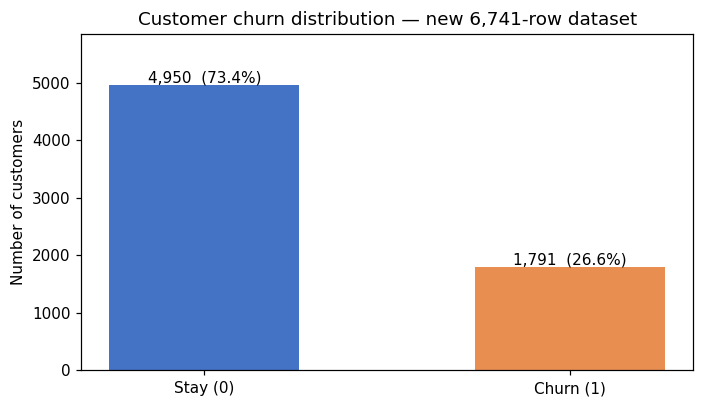

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
labels = ["Stay (0)", "Churn (1)"]
bars = ax.bar(labels, counts.values, color=["#4472C4", "#E88E51"], width=0.52)
for rect, n in zip(bars, counts.values):
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height()+50,
            f"{int(n):,}  ({n/len(clean)*100:.1f}%)", ha="center")
ax.set_ylim(0, max(counts.values)*1.18)
ax.set_ylabel("Number of customers")
ax.set_title("Customer churn distribution — new 6,741-row dataset")
fig.tight_layout()
fig.savefig(OUT / "01_churn_distribution.png", bbox_inches="tight")
plt.show()

## 3.3 Identical inputs with different churn outcomes

**Objective.** Investigate a limitation not captured by the exact-duplicate check.

**Method.** Compare all 10 input features, **excluding `Churn`**. If two feature-identical records have opposite outcomes, they are *not exact duplicate rows*. They may be distinct customers with the same measured profile, or there may be missing explanatory variables.

**Why this matters for ANN.** A deterministic ANN produces the same predicted probability for the same feature vector. It cannot correctly label both members of a contradictory pair at a fixed threshold. These records are **retained** for analysis; identical feature profiles are assigned to the same training, validation or test partition.

### How was the “100 pairs” result discovered?

This is a **data-quality diagnostic**, **not a prediction made by the ANN**. Records were grouped by their complete set of *input* features, excluding the target (`Churn`). A group was flagged if it contained both target outcomes (0 and 1). There are exactly **100 such groups**, each consisting of **two rows**. Unlike the 302 fully duplicated rows removed by Data Engineering, these pairs differ in the *label*, so they correctly remain after exact deduplication. Their presence does **not prove an error**: there is no CustomerID to tell whether similar profiles are different people.

**Implication:** Because their 10 observed features are identical, a deterministic ANN has no way to assign different probabilities to the two members of a pair. This characteristic is documented as a limitation of the available predictive inputs.


In [4]:
input_cols_stage2 = [c for c in clean.columns if c != "Churn"]
profile_group = pd.factorize(pd.MultiIndex.from_frame(clean[input_cols_stage2]), sort=False)[0]
audit = clean.assign(_profile_group=profile_group).groupby("_profile_group")["Churn"].agg(["size", "nunique"])
contradictory = audit[(audit["nunique"] > 1)]
print(f"Identical-feature groups with opposite Churn labels: {len(contradictory):,}")
print(f"Records within these groups: {int(contradictory['size'].sum()):,}")
if len(contradictory):
    first = contradictory.index[0]
    rows = np.flatnonzero(profile_group == first)
    print("\nIllustrative example (row numbers in CSV, counting header as row 1):")
    example = clean.iloc[rows].copy()
    example.insert(0, "Excel_Row", rows + 2)
    print(example.to_string(index=False))
assert len(contradictory) == 100, "Unexpected number of contradictory feature profiles. Recheck supplied data."
assert int(contradictory["size"].sum()) == 200
# Export all 100 groups as independently checkable evidence.
# Row number = pandas index + 2 (Excel row 1 contains the CSV header).
audit_records = clean.copy()
audit_records.insert(0, "Excel_Row", np.arange(len(clean)) + 2)
audit_records.insert(0, "Feature_Profile_ID", profile_group)
conflicting_rows = audit_records[audit_records["Feature_Profile_ID"].isin(contradictory.index)].copy()
conflicting_rows = conflicting_rows.sort_values(["Feature_Profile_ID", "Churn"])
conflicting_rows["Pair_Number"] = pd.factorize(conflicting_rows["Feature_Profile_ID"])[0] + 1
conflicting_rows.to_csv(OUT / "100_Conflicting_Churn_Pairs_Full_Evidence.csv", index=False)
assert len(conflicting_rows) == 200 and conflicting_rows["Pair_Number"].nunique() == 100
print("Saved all 200 affected rows across 100 contradictory pairs.")
print("First three pairs (Excel row numbers and outcomes):")
print(conflicting_rows.groupby("Pair_Number").head(2)[["Pair_Number", "Excel_Row", "Churn"]].head(6).to_string(index=False))


Identical-feature groups with opposite Churn labels: 100
Records within these groups: 200

Illustrative example (row numbers in CSV, counting header as row 1):
 Excel_Row gender  SeniorCitizen Dependents    tenure  MonthlyCharges  Churn  PhoneService_Yes  MultipleLines_Yes  InternetService_Fiber optic  Contract_One year  Contract_Two year
         2 Female      -0.448765         No -1.312875       -1.376228      1             False              False                        False              False              False
      5896 Female      -0.448765         No -1.312875       -1.376228      0             False              False                        False              False              False
Saved all 200 affected rows across 100 contradictory pairs.
First three pairs (Excel row numbers and outcomes):
 Pair_Number  Excel_Row  Churn
           1       5896      0
           1          2      1
           2       2369      0
           2         11      1
           3         12      0

## 3.4 ANN-specific feature encoding

**Objective.** Make the input features numeric and interpretable.

**Decisions.**
- `gender`: Male = **1**, Female = **0**.
- `Dependents`: Yes = **1**, No = **0**.
- `SeniorCitizen`: **retain as a 0/1 binary flag**, restoring the source indicator from its two standardised values. **Do not** use `.astype(int)` directly on standardised values, since that would produce incorrect categories.
- Phone, multiple lines, fibre internet and contract indicators: True = **1**, False = **0**.
- `tenure` and `MonthlyCharges`: continuous numeric features; rescale based on **training data only** in Section 3.6.
- `Churn`: the target label, **never** part of the model inputs. `Cluster` is also excluded from Model A.

**Source-specific note.** The supplied dataset already contains standardised continuous values computed upstream. Re-standardising this *affine-scaled* data using training-only statistics is mathematically equivalent to standardising the original continuous values using training-only statistics (subject to numerical precision). If upstream preprocessing included nonlinear or data-dependent operations, the original raw data would be needed for a full audit.

### Rationale for retaining `SeniorCitizen` as a binary feature

The Data Engineer indicated that the original standardisation was intended to support outlier identification during data preparation. Standardised scores can be helpful for screening unusual values in *continuous* variables. However, `SeniorCitizen` represents a valid binary category: **0 = non-senior; 1 = senior**. A relatively high standardised value for the senior category primarily reflects its lower frequency, and does not by itself indicate a data error or an anomalous customer. Accordingly, the ANN preprocessing procedure restores and retains the original 0/1 representation to maintain categorical interpretability and consistency with other binary indicators. Standardising binary inputs is not inherently invalid in all modelling contexts; retaining the binary flag is a deliberate methodological choice for this experiment. Only the continuous variables `tenure` and `MonthlyCharges` are standardised, with scaling parameters estimated from **training data only**.


In [5]:
df = clean.copy()
assert set(df["gender"].unique()) == {"Female", "Male"}
assert set(df["Dependents"].unique()) == {"No", "Yes"}
raw_senior_codes = np.sort(df["SeniorCitizen"].unique())
assert len(raw_senior_codes) == 2 and raw_senior_codes[0] < 0 < raw_senior_codes[1]

df["gender"] = df["gender"].map({"Female":0, "Male":1}).astype("int8")
df["Dependents"] = df["Dependents"].map({"No":0, "Yes":1}).astype("int8")
df["SeniorCitizen"] = (df["SeniorCitizen"] > 0).astype("int8")
bool_cols = df.select_dtypes(include=["bool"]).columns.tolist()
df[bool_cols] = df[bool_cols].astype("int8")
feature_cols = [col for col in df.columns if col != "Churn"]
continuous_cols = ["tenure", "MonthlyCharges"]

print("SeniorCitizen codes from supplied file:", raw_senior_codes)
print("Features for Model A:", feature_cols)
print("\nFirst 5 encoded customer records:")
print(df.head().to_string(index=False))
assert df[feature_cols].notna().all().all()
assert len(feature_cols) == 10

SeniorCitizen codes from supplied file: [-0.44876511  2.22833721]
Features for Model A: ['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'MonthlyCharges', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'Contract_One year', 'Contract_Two year']

First 5 encoded customer records:
 gender  SeniorCitizen  Dependents    tenure  MonthlyCharges  Churn  PhoneService_Yes  MultipleLines_Yes  InternetService_Fiber optic  Contract_One year  Contract_Two year
      0              0           0 -1.312875       -1.376228      1                 0                  0                            0                  0                  0
      1              0           0  0.331038       -1.376228      0                 1                  0                            0                  1                  0
      0              0           1  0.783114       -1.578399      0                 1                  0                            0                  0                  0
     

## 3.5 Training / validation / test split — 70% / 20% / 10%

**Objective.** Learn from 70% of customers, use a separate **20% validation set** for early stopping, hyperparameter choice and threshold selection, then evaluate **once** using a **10% independent test set**.

**Rationale for the 70/20/10 split.** The 80/20 training/testing approach prepared during data engineering is a valid starting point and can be supplemented with internal validation or cross-validation. For this ANN study, an explicit **70% training / 20% validation / 10% test** partition separates model fitting, early stopping and threshold selection from independent final evaluation. Repeated tuning against the test set could otherwise produce overly optimistic results. The smaller test partition (approximately 674 records) also means performance estimates may be less precise. Neither split is inherently superior; the three-way structure was selected to support the stated evaluation workflow.

**Method.** Use `StratifiedGroupKFold` with **10 near-equal folds**: **7 folds training**, **2 folds validation**, **1 fold testing**. This gives approximately 70/20/10, preserves the churn ratio and keeps all records with **identical feature vectors** together. The group label is an internal grouping key, *not a CustomerID*. The exact same independent validation and test customer identities will be used for the 7,043-vs-6,741 sensitivity analysis.


In [6]:
X_all = df[feature_cols].copy()
y_all = df["Churn"].astype(int).to_numpy()
groups = profile_group

# Stratified, group-aware 10-fold partition: 7 train, 2 validation, 1 test.
fold_gen = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = [test for _, test in fold_gen.split(X_all, y_all, groups)]
test_idx = folds[0]
val_idx = np.sort(np.concatenate([folds[1], folds[2]]))
train_idx = np.sort(np.concatenate(folds[3:]))

splits = {"Train": train_idx, "Validation": val_idx, "Test": test_idx}
assert len(np.unique(np.concatenate(list(splits.values())))) == len(df)
assert len(set(groups[train_idx]) & set(groups[val_idx])) == 0
assert len(set(groups[train_idx]) & set(groups[test_idx])) == 0
assert len(set(groups[val_idx]) & set(groups[test_idx])) == 0
split_summary = pd.DataFrame({
    "Split": list(splits),
    "Customers": [len(v) for v in splits.values()],
    "Share (%)": [round(100*len(v)/len(df), 2) for v in splits.values()],
    "Churn (%)": [round(100*y_all[v].mean(), 2) for v in splits.values()],
})
print(split_summary.to_string(index=False))
print("Feature-identical profiles shared across splits: 0 (verified).")
pd.DataFrame({"New_CSV_Row_Including_Header":np.arange(len(clean))+2,
              "Set":np.where(np.isin(np.arange(len(clean)), test_idx), "Test",
                     np.where(np.isin(np.arange(len(clean)), val_idx), "Validation", "Train")),
              "Churn":y_all}).to_csv(OUT / "Common_70_20_10_Split_Registry.csv",index=False)

train_x_raw, val_x_raw, test_x_raw = (X_all.iloc[idx].reset_index(drop=True) for idx in (train_idx, val_idx, test_idx))
y_train, y_val, y_test = (y_all[idx] for idx in (train_idx, val_idx, test_idx))


     Split  Customers  Share (%)  Churn (%)
     Train       4719       70.0      26.57
Validation       1348       20.0      26.56
      Test        674       10.0      26.56
Feature-identical profiles shared across splits: 0 (verified).


## 3.6 Fit the numerical scaler on training data only

**Objective.** Give `tenure` and `MonthlyCharges` comparable scales without letting validation/test statistics affect training.

**Method.** Fit `StandardScaler` on the training rows only. Apply the fitted transformation to validation and test. Leave all binary flags at 0 or 1.

**Interpretation.** This prevents an avoidable form of **data leakage**. An individual customer with a lower-than-average tenure may have a negative standardised value; this is not an invalid record.

In [7]:
scaler = StandardScaler()
scaler.fit(train_x_raw[continuous_cols])

def make_scaled_features(frame):
    out = frame.copy()
    out.loc[:, continuous_cols] = scaler.transform(out[continuous_cols])
    return out.astype("float32")

Xa_train = make_scaled_features(train_x_raw)
Xa_val = make_scaled_features(val_x_raw)
Xa_test = make_scaled_features(test_x_raw)
print("Training mean after scaling (continuous columns):", np.round(Xa_train[continuous_cols].mean().to_numpy(), 5))
print("Training std after scaling (continuous columns):", np.round(Xa_train[continuous_cols].std(ddof=0).to_numpy(), 5))
print("Model A input shape:", Xa_train.shape)
assert set(np.unique(Xa_train["SeniorCitizen"])) == {0.0, 1.0}

Training mean after scaling (continuous columns): [0. 0.]
Training std after scaling (continuous columns): [1. 1.]
Model A input shape: (4719, 10)


## 3.7 K-Means labels for ANN Model B — without test-set leakage

**Objective.** Compare an ANN based on original customer features (**Model A**) against the same ANN plus four one-hot cluster indicators (**Model B**).

**Method.** The supplied Stage 2 cluster labels were produced from the full 6,741-row dataset. These full-data labels are retained as a **descriptive reference only**. For a fair predictive comparison, refit **K = 4** K-Means using the **training set only**, with the nine features specified in the Stage 2 clustering analysis (excluding gender and the churn target). Then assign validation/test customers using the training-only cluster model. Labels are reordered by increasing average tenure and then monthly charges to approximate the C0–C3 naming conventions in the report prepared by the Data Analyst (Clustering).

**Why this matters.** Otherwise the test customers would indirectly influence the cluster construction. Model B gets four one-hot cluster indicators, **not** the integer label 0, 1, 2 or 3 as a continuous numerical quantity. All models use identical train/validation/test rows.

In [8]:
cluster_features = [
    "tenure", "MonthlyCharges", "SeniorCitizen", "Dependents",
    "PhoneService_Yes", "MultipleLines_Yes", "InternetService_Fiber optic",
    "Contract_One year", "Contract_Two year"
]
km = KMeans(n_clusters=4, n_init=10, init="k-means++", random_state=SEED)
raw_train_clusters = km.fit_predict(Xa_train[cluster_features])
raw_val_clusters = km.predict(Xa_val[cluster_features])
raw_test_clusters = km.predict(Xa_test[cluster_features])

center_profiles = (
    train_x_raw.assign(_km=raw_train_clusters)
    .groupby("_km")[["tenure", "MonthlyCharges"]].mean()
    .sort_values(["tenure", "MonthlyCharges"])
)
cluster_map = {int(old):int(i) for i, old in enumerate(center_profiles.index)}
remap = lambda a: np.array([cluster_map[int(x)] for x in a], dtype=int)
ct, cv, cs = [remap(z) for z in (raw_train_clusters, raw_val_clusters, raw_test_clusters)]

# One-hot encoding, with exactly four columns including missing-in-split clusters.
cluster_columns = [f"Cluster_C{i}" for i in range(4)]
def with_one_hot_clusters(original, labels):
    extra = pd.DataFrame(np.eye(4, dtype=np.float32)[labels], columns=cluster_columns)
    return pd.concat([original.reset_index(drop=True), extra], axis=1)

Xb_train = with_one_hot_clusters(Xa_train, ct)
Xb_val = with_one_hot_clusters(Xa_val, cv)
Xb_test = with_one_hot_clusters(Xa_test, cs)

print("Model A inputs:", Xa_train.shape[1], "features")
print("Model B inputs:", Xb_train.shape[1], "features")
print("Training-derived cluster sizes:", pd.Series(ct).value_counts().sort_index().to_dict())
print("Stage 2 supplied cluster sizes (descriptive reference):",
      with_clusters["Cluster"].value_counts().sort_index().to_dict())
assert len(Xb_train) == len(Xa_train) and len(Xb_test) == len(Xa_test)

Model A inputs: 10 features
Model B inputs: 14 features
Training-derived cluster sizes: {0: 1123, 1: 1484, 2: 791, 3: 1321}
Stage 2 supplied cluster sizes (descriptive reference): {0: 1592, 1: 2139, 2: 1127, 3: 1883}


### ANN architecture and why it was selected

**Objective.** Train a reasonably small network appropriate for a dataset of about 6,700 rows, with **binary churn probability** as the output.

**Initial architecture** (same design for both models):

| Layer | Configuration | Plain-English reason |
|---|---|---|
| Input | 10 variables (A) or 14 (B) | Represent customer information |
| Hidden 1 | 32 neurons, ReLU | Learn useful combinations of customer features |
| Dropout | 15% | Reduce reliance on individual neurons |
| Hidden 2 | 16 neurons, ReLU | Learn more compact patterns |
| Output | 1 neuron, sigmoid | Produce estimated churn probability 0–1 |
| Loss | Binary cross-entropy | Appropriate for two-class prediction |
| Optimiser | Adam, learning rate 0.001 | Efficient iterative optimisation |
| Regularisation | L2 penalty + early stopping | Reduce overfitting |

**Important caveat:** More complex does not necessarily mean more accurate. Model performance is benchmarked against a majority-class classifier and Logistic Regression. Because the dataset is imbalanced, **class weights are computed using training data only**. Only the validation set informs early stopping and decision-threshold tuning.

In [9]:
class_weights_values = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)
class_weights = {0:float(class_weights_values[0]), 1:float(class_weights_values[1])}
print("Training class weights:", {k:round(v, 3) for k,v in class_weights.items()})

def build_ann(n_features, seed):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
        layers.Dropout(0.15),
        layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="roc_auc")])
    return model

def train_ann(X_train, X_val, seed):
    model = build_ann(X_train.shape[1], seed)
    history = model.fit(
        X_train.to_numpy(dtype=np.float32), y_train,
        validation_data=(X_val.to_numpy(dtype=np.float32), y_val),
        epochs=65, batch_size=256, verbose=0,
        class_weight=class_weights,
        callbacks=[
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
        ]
    )
    return model, history

Training class weights: {0: 0.681, 1: 1.882}


## 3.8 Train ANN Model A — original customer information

**Objective.** Establish churn prediction using the ten encoded customer attributes without cluster labels.

**Evidence.** Training and validation losses are plotted to monitor the learning process. If training loss falls but validation loss rises, the network may be overfitting. The training process stops early when the validation loss stops improving.

**Do not confuse:** A decreasing loss chart shows the learning process, **not** test performance.

ANN A epochs trained: 37
ANN A minimum validation loss: 0.5583


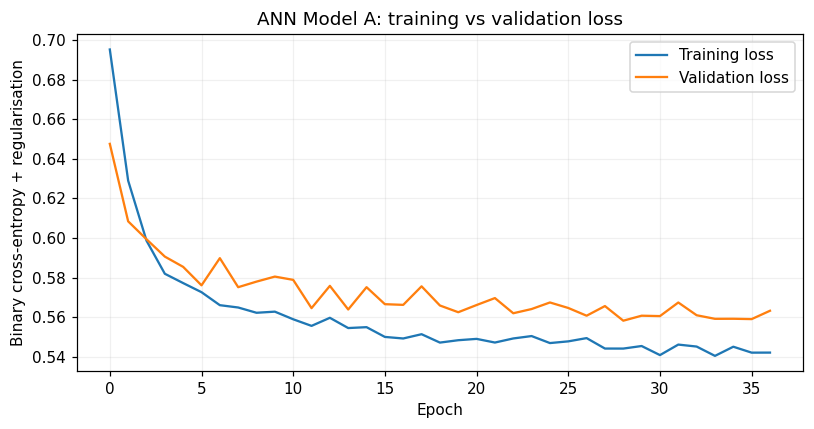

In [10]:
ann_a, history_a = train_ann(Xa_train, Xa_val, SEED)
print("ANN A epochs trained:", len(history_a.history["loss"]))
print("ANN A minimum validation loss:", round(min(history_a.history["val_loss"]), 4))

def plot_learning(history, title, filename):
    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.plot(history.history["loss"], label="Training loss")
    ax.plot(history.history["val_loss"], label="Validation loss")
    ax.set(xlabel="Epoch", ylabel="Binary cross-entropy + regularisation",
           title=title)
    ax.legend(); ax.grid(alpha=0.18)
    fig.tight_layout(); fig.savefig(OUT/filename, bbox_inches="tight")
    plt.show()
plot_learning(history_a, "ANN Model A: training vs validation loss", "02_ann_a_learning.png")

## 3.9 Train ANN Model B — original features + customer cluster

**Objective.** Test whether customer segmentation gives the ANN **extra predictive value** beyond the original customer attributes.

**Method.** ANN B has the **same architecture**, training schedule and splitting as ANN A, except for four additional one-hot cluster columns derived from **training-only K-Means**.

**Interpretation rule.** If Model B's ROC-AUC or recall is only slightly different, do not claim that clusters materially improve the predictions. Assess improvement on **unseen test customers** and consider the added complexity.

ANN B epochs trained: 20
ANN B minimum validation loss: 0.5625


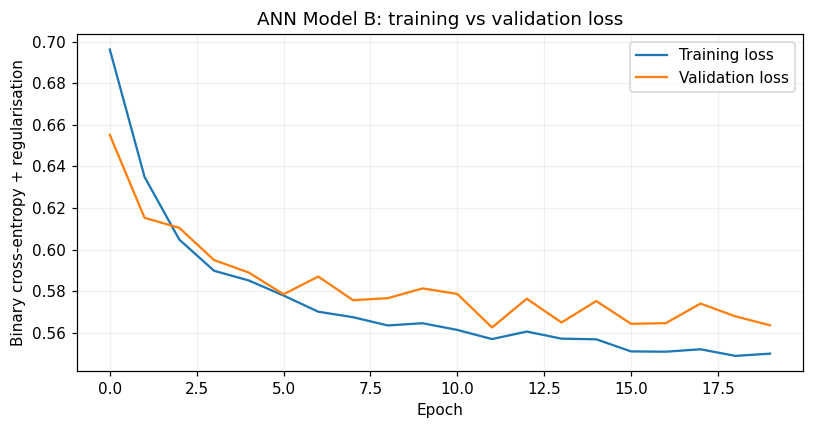

In [11]:
ann_b, history_b = train_ann(Xb_train, Xb_val, SEED)
print("ANN B epochs trained:", len(history_b.history["loss"]))
print("ANN B minimum validation loss:", round(min(history_b.history["val_loss"]), 4))
plot_learning(history_b, "ANN Model B: training vs validation loss", "03_ann_b_learning.png")

## 3.10 Baseline and model evaluation

**Objective.** Compare models on identical data using metrics that matter for the business.

**Benchmarks.** 
- **Majority class:** predicts everyone stays. High apparent accuracy can be misleading.
- **Logistic Regression:** simple interpretable predictive baseline, with balanced class weights.
- **ANN A:** customer characteristics only.
- **ANN B:** customer characteristics + training-derived cluster indicators.

**Metrics and their meaning:**

| Metric | Plain-English question |
|---|---|
| Accuracy | How many predictions are correct overall? |
| Precision (churn) | Of customers flagged as likely to churn, how many did? |
| Recall (churn) | What proportion of actual churners was correctly identified? |
| F1-score | How well do precision and recall balance? |
| ROC-AUC | How well can the model rank churners above non-churners across thresholds? |
| PR-AUC | How well does the model identify the minority churn class across thresholds? |

**Decision threshold.** Both the standard **0.50** threshold and a separate F1-maximising threshold selected **using validation data only** are reported. The test set is never used to select thresholds. The business might prefer higher recall if missing churners is more costly, but that usually increases false alarms.

In [12]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(Xa_train, y_train)
logreg = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)
logreg.fit(Xa_train, y_train)

# Probability predictions on independent validation and test rows.
def pred_prob(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.predict(X.to_numpy(dtype=np.float32), batch_size=2048, verbose=0).reshape(-1)

models = {
    "Majority baseline": (dummy, Xa_val, Xa_test),
    "Logistic Regression": (logreg, Xa_val, Xa_test),
    "ANN A — No Cluster": (ann_a, Xa_val, Xa_test),
    "ANN B — With Cluster": (ann_b, Xb_val, Xb_test),
}
prob_val = {name:pred_prob(model, xv) for name, (model,xv,_) in models.items()}
prob_test = {name:pred_prob(model, xt) for name, (model,_,xt) in models.items()}

def threshold_from_validation(y_true, prob):
    thresholds = np.linspace(0.1, 0.9, 161)
    values = [f1_score(y_true, prob >= t, zero_division=0) for t in thresholds]
    return float(thresholds[int(np.argmax(values))])

chosen_thresholds = {name:threshold_from_validation(y_val, p)
                     for name, p in prob_val.items() if name != "Majority baseline"}
print("F1-optimal validation thresholds:", {k:round(v, 3) for k,v in chosen_thresholds.items()})

def evaluate(name, y_true, prob, threshold):
    preds = (prob >= threshold).astype(int)
    return {
        "Model": name, "Threshold":round(float(threshold), 3),
        "Accuracy":accuracy_score(y_true, preds),
        "Balanced accuracy": balanced_accuracy_score(y_true, preds),
        "Precision":precision_score(y_true, preds, zero_division=0),
        "Recall":recall_score(y_true, preds, zero_division=0),
        "F1-score":f1_score(y_true, preds, zero_division=0),
        "ROC-AUC":roc_auc_score(y_true, prob) if len(np.unique(prob))>1 else 0.5,
        "PR-AUC":average_precision_score(y_true, prob)
    }

rows05 = [evaluate(name, y_test, p, 0.5) for name,p in prob_test.items()]
comparison05 = pd.DataFrame(rows05).set_index("Model")
print("\nTEST COMPARISON — fixed 0.50 threshold:")
print(comparison05.round(4).to_string())
comparison05.to_csv(OUT / "ANN_Model_Comparison_Threshold_0_50.csv")

rowstuned = [evaluate(name, y_test, p, chosen_thresholds[name])
             for name,p in prob_test.items() if name != "Majority baseline"]
comparison_tuned = pd.DataFrame(rowstuned).set_index("Model")
print("\nTEST COMPARISON — thresholds selected from VALIDATION for F1:")
print(comparison_tuned.round(4).to_string())
comparison_tuned.to_csv(OUT / "ANN_Model_Comparison_Validation_Tuned.csv")

F1-optimal validation thresholds: {'Logistic Regression': 0.625, 'ANN A — No Cluster': 0.655, 'ANN B — With Cluster': 0.63}

TEST COMPARISON — fixed 0.50 threshold:
                      Threshold  Accuracy  Balanced accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC
Model                                                                                                     
Majority baseline           0.5    0.7344             0.5000     0.0000  0.0000    0.0000   0.5000  0.2656
Logistic Regression         0.5    0.7122             0.7238     0.4735  0.7486    0.5801   0.7958  0.5754
ANN A — No Cluster          0.5    0.7151             0.7294     0.4772  0.7598    0.5862   0.7941  0.5770
ANN B — With Cluster        0.5    0.7181             0.7207     0.4797  0.7263    0.5778   0.7924  0.5709

TEST COMPARISON — thresholds selected from VALIDATION for F1:
                      Threshold  Accuracy  Balanced accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC
Model                  

### Interpretation guidance — model comparison

- Compare **ROC-AUC** and **PR-AUC** to assess ranking performance independently of a 0.50 decision cutoff.
- Compare **Recall** to understand missed churners, and **Precision** to understand false alarms among flagged customers.
- A **false negative** (actual churner predicted to stay) is a missed retention opportunity. A **false positive** (customer predicted to churn but stayed) could lead to unnecessary retention spending.
- The final decision should not rely on small differences from one random split alone. A future extension could repeat grouped splits or use nested/group-aware cross-validation.

The next code cell prints an interpretation based on the **actual values just computed**.

In [13]:
A = comparison05.loc["ANN A — No Cluster"]
B = comparison05.loc["ANN B — With Cluster"]
print(f"At the fixed 0.50 threshold, ANN A achieved recall {A['Recall']:.1%}, "
      f"F1 {A['F1-score']:.1%}, and ROC-AUC {A['ROC-AUC']:.3f}.")
print(f"ANN B achieved recall {B['Recall']:.1%}, F1 {B['F1-score']:.1%}, "
      f"and ROC-AUC {B['ROC-AUC']:.3f}.")
print(f"Adding clusters changed ROC-AUC by {B['ROC-AUC']-A['ROC-AUC']:+.4f}, "
      f"recall by {B['Recall']-A['Recall']:+.1%} points, "
      f"and F1 by {B['F1-score']-A['F1-score']:+.1%} points on this test split.")
print("These figures show association and predictive performance, not the causes of customer churn.")

At the fixed 0.50 threshold, ANN A achieved recall 76.0%, F1 58.6%, and ROC-AUC 0.794.
ANN B achieved recall 72.6%, F1 57.8%, and ROC-AUC 0.792.
Adding clusters changed ROC-AUC by -0.0018, recall by -3.4% points, and F1 by -0.8% points on this test split.
These figures show association and predictive performance, not the causes of customer churn.


## 3.11 Visual evidence: confusion matrices and ROC / PR curves

**Objective.** Move beyond reporting metrics as isolated numbers, addressing Stage 2 teacher feedback.

**Confusion matrices.** Explain correct predictions and both types of errors. In the business setting, the cost of missing a churner may differ from the cost of contacting someone who would stay.

**ROC and precision-recall curves.** Show ranking quality over multiple thresholds; PR curves are particularly informative for an imbalanced outcome.

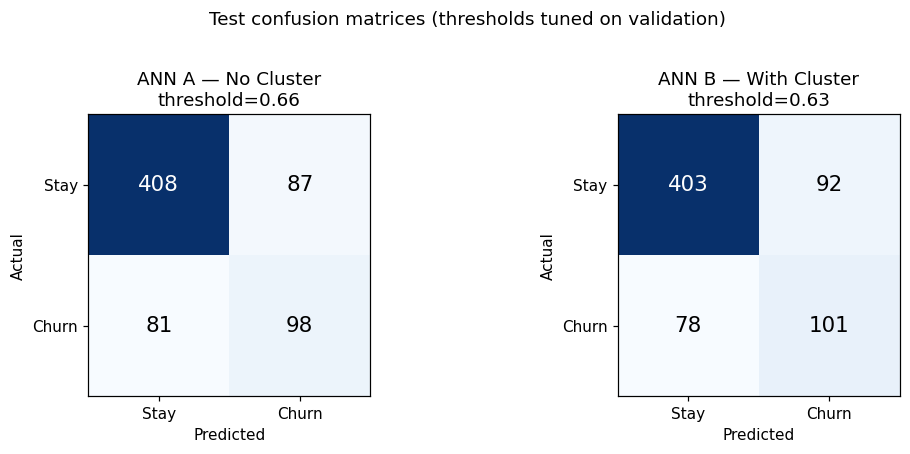

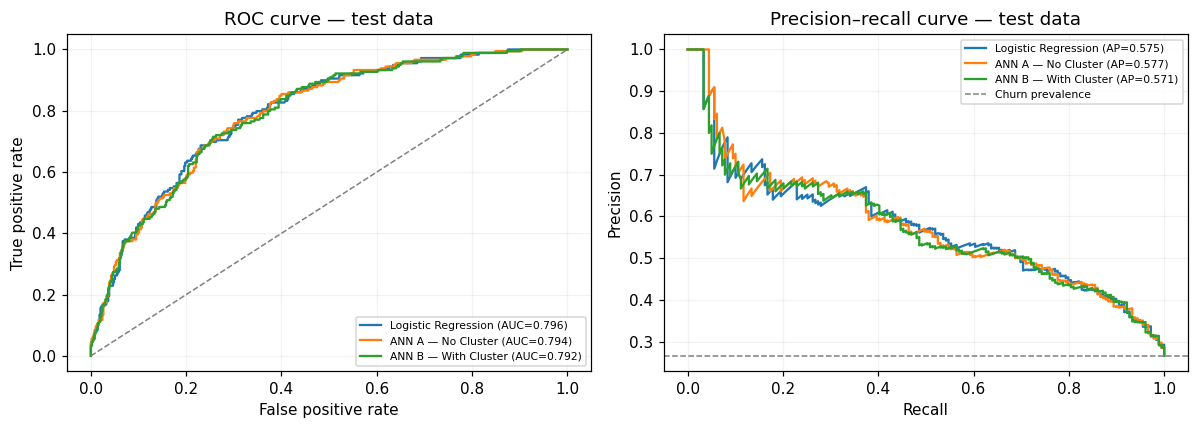

In [14]:
plot_names = ["ANN A — No Cluster", "ANN B — With Cluster"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, plot_names):
    y_pred = (prob_test[name] >= chosen_thresholds[name]).astype(int)
    matrix = confusion_matrix(y_test, y_pred, labels=[0,1])
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i,j]:,}", ha="center", va="center", fontsize=14,
                    color="white" if matrix[i,j] > matrix.max()/2 else "black")
    ax.set(title=f"{name}\nthreshold={chosen_thresholds[name]:.2f}",
           xlabel="Predicted", ylabel="Actual", xticks=[0,1], yticks=[0,1],
           xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
fig.suptitle("Test confusion matrices (thresholds tuned on validation)", y=1.02)
fig.tight_layout(); fig.savefig(OUT/"04_confusion_matrices.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11,4))
for name in ["Logistic Regression"]+plot_names:
    p=prob_test[name]
    fpr,tpr,_=roc_curve(y_test, p)
    precision,recall,_=precision_recall_curve(y_test,p)
    axes[0].plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_test,p):.3f})")
    axes[1].plot(recall,precision,label=f"{name} (AP={average_precision_score(y_test,p):.3f})")
axes[0].plot([0,1],[0,1],"--",c="gray",lw=1)
axes[1].axhline(y=y_test.mean(),ls="--",c="gray",lw=1,label="Churn prevalence")
axes[0].set(title="ROC curve — test data",xlabel="False positive rate",ylabel="True positive rate")
axes[1].set(title="Precision–recall curve — test data",xlabel="Recall",ylabel="Precision")
for ax in axes: ax.grid(alpha=.16); ax.legend(fontsize=7,loc="best")
fig.tight_layout();fig.savefig(OUT/"05_roc_pr_curves.png",bbox_inches="tight")
plt.show()

## 3.12 Which customer features matter? (descriptive model explanation)

**Objective.** Give business stakeholders more than a single performance score.

**Method.** Use **permutation importance on the validation set** for ANN A. One feature is shuffled at a time while the remaining features are held unchanged; the resulting decrease in ROC-AUC is measured. Larger drops suggest the feature contributes more information to this model's predictions. This is a **model-based association**, not proof that changing the feature would prevent churn.

**Caution.** If two features are strongly related, permutation results can underestimate each feature's separate contribution. This analysis is descriptive and is not used to select features using the test set.

                    Feature  Mean ROC-AUC drop  Std drop
                     tenure             0.2129    0.0057
             MonthlyCharges             0.1153    0.0020
              SeniorCitizen             0.0074    0.0021
           PhoneService_Yes             0.0072    0.0011
                 Dependents             0.0021    0.0015
          Contract_One year             0.0016    0.0005
InternetService_Fiber optic             0.0013    0.0006
                     gender             0.0004    0.0019
          MultipleLines_Yes            -0.0012    0.0004
          Contract_Two year            -0.0014    0.0005


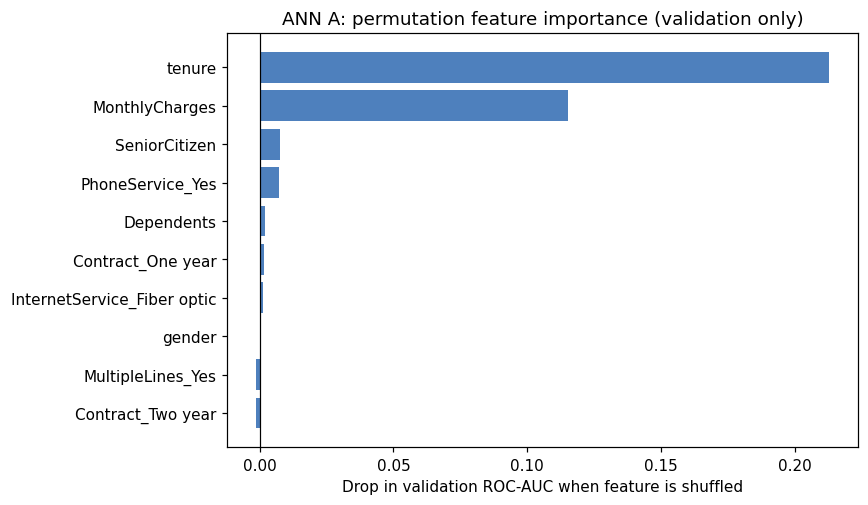

In [15]:
rng = np.random.default_rng(SEED)
base_auc = roc_auc_score(y_val, prob_val["ANN A — No Cluster"])
importances=[]
for j,col in enumerate(feature_cols):
    perm_drops=[]
    for _ in range(2):
        X_perm=Xa_val.to_numpy(dtype=np.float32).copy()
        X_perm[:,j]=rng.permutation(X_perm[:,j])
        p=ann_a.predict(X_perm,batch_size=2048,verbose=0).reshape(-1)
        perm_drops.append(base_auc - roc_auc_score(y_val,p))
    importances.append((col, np.mean(perm_drops), np.std(perm_drops)))
importance_df=pd.DataFrame(importances,columns=["Feature","Mean ROC-AUC drop","Std drop"])
importance_df=importance_df.sort_values("Mean ROC-AUC drop",ascending=False)
print(importance_df.round(4).to_string(index=False))
importance_df.to_csv(OUT / "ANN_A_Feature_Importance_Validation.csv",index=False)
fig,ax=plt.subplots(figsize=(8,4.7))
bar_values=importance_df.iloc[::-1]
ax.barh(bar_values["Feature"],bar_values["Mean ROC-AUC drop"],color="#4E80BD")
ax.axvline(0,c="black",lw=.8)
ax.set(xlabel="Drop in validation ROC-AUC when feature is shuffled",title="ANN A: permutation feature importance (validation only)")
fig.tight_layout();fig.savefig(OUT/"06_feature_importance.png",bbox_inches="tight")
plt.show()

## 3.13 Segment-level performance and business implications

**Objective.** Connect ANN predictions back to the customer groups defined by the Data Analyst (Clustering), especially **At-Risk New Premium Customers (C1)**.

**Method.** Evaluate ANN B by the four **training-derived** clusters on the test set. This is not an independent evaluation of the full-data cluster labels supplied by the Data Analyst (Clustering); the labels approximate the same C0–C3 business naming scheme but may differ slightly because K-Means was refitted using training records only.

**Why this matters.** A useful model should not only perform acceptably overall; it should also identify potential churners in high-priority segments. Segment results need caution when a group has relatively few churners.

In [16]:
name_map={0:"C0 — New Budget",1:"C1 — At-Risk New Premium",2:"C2 — Loyal Budget",3:"C3 — Loyal Premium"}
segment_rows=[]
p_b=prob_test["ANN B — With Cluster"]
yp_b=(p_b>=chosen_thresholds["ANN B — With Cluster"]).astype(int)
for k in range(4):
    mask=(cs==k)
    yy=y_test[mask]
    pp=yp_b[mask]
    segment_rows.append({
        "Segment":name_map[k], "Test customers":int(mask.sum()),
        "Observed churn (%)":float(100*yy.mean()) if len(yy) else np.nan,
        "Recall":float(recall_score(yy,pp,zero_division=0)) if len(yy) else np.nan,
        "Precision":float(precision_score(yy,pp,zero_division=0)) if len(yy) else np.nan,
        "Predicted at risk":int(pp.sum())
    })
segment_df=pd.DataFrame(segment_rows)
print(segment_df.round(3).to_string(index=False))
segment_df.to_csv(OUT / "ANN_B_Test_Performance_By_TrainDerived_Segment.csv",index=False)

                 Segment  Test customers  Observed churn (%)  Recall  Precision  Predicted at risk
         C0 — New Budget             183              25.137   0.370      0.459                 37
C1 — At-Risk New Premium             213              46.009   0.827      0.547                148
       C2 — Loyal Budget              99               6.061   0.000      0.000                  0
      C3 — Loyal Premium             179              16.201   0.103      0.375                  8


## 3.14 Save results, limitations and next steps

**Reproducibility.** Save models, training-only scaler, training-only K-Means and its label ordering, metrics, test predictions and supporting figures. All test prediction row numbers refer to positions in the supplied CSV; they are **not customer IDs**.

**Limitations to report honestly:**
1. **Single snapshot** of customer attributes, not time-series behaviour. Missing usage history, billing history, complaints and payment method data.
2. **No CustomerID** to verify that all removed “duplicate” records represented the same actual customer.
3. **100 contradictory feature profiles** (200 records) with opposite churn outcomes: the observed features cannot distinguish each pair.
4. **Class imbalance** (roughly 26.6% churn), so accuracy alone is insufficient.
5. **One grouped 70/20/10 holdout split.** Model superiority should be confirmed with further repeats before production decisions.
6. **Stage 2 preprocessing already standardised continuous features**, so the notebook fits a second training-only scaler to correct the effective modelling scale. Original raw data would allow a cleaner end-to-end pipeline.
7. **Train-only K-Means labels are not exactly the full-data labels supplied by the Data Analyst (Clustering)**; segment names are approximate, ordered using tenure and monthly charge.
8. **Prediction does not prove causation.** Targeted retention strategies require business validation and appropriate safeguards.

**Next steps:** Validate the metrics, review the false negatives, select an appropriate risk threshold based on retention capacity, and hand over results to Fahad (Business Analyst) for segment-specific recommendations.

In [17]:
ann_a.save(OUT/"ann_model_a_no_cluster.keras")
ann_b.save(OUT/"ann_model_b_with_cluster.keras")
joblib.dump(scaler, OUT/"train_only_continuous_scaler.joblib")
joblib.dump({"model":km,"cluster_map":cluster_map,"features":cluster_features},
            OUT/"train_only_kmeans_and_mapping.joblib")
joblib.dump(logreg, OUT/"logistic_regression_baseline.joblib")

predictions=pd.DataFrame({
    "CSV_row_number_including_header":test_idx+2,
    "Actual_Churn":y_test,
    "Training_Derived_Cluster":cs,
    "Probability_ANN_A":prob_test["ANN A — No Cluster"],
    "Probability_ANN_B":prob_test["ANN B — With Cluster"],
    "Predicted_ANN_A":(prob_test["ANN A — No Cluster"]>=chosen_thresholds["ANN A — No Cluster"]).astype(int),
    "Predicted_ANN_B":(prob_test["ANN B — With Cluster"]>=chosen_thresholds["ANN B — With Cluster"]).astype(int),
})
predictions.to_csv(OUT/"ANN_Test_Predictions.csv",index=False)

manifest={
 "stage":"Part 3 - ANN Churn Prediction", "prepared_by":"Bao Ngoc Nguyen",
 "dataset":"Updated_Dataset (1).csv", "rows":len(clean),"random_seed":SEED,
 "keras_backend":keras.backend.backend(),
 "class_weights":class_weights, "feature_cols":feature_cols,
 "cluster_features":cluster_features,
 "thresholds_selected_on_validation":chosen_thresholds,
 "split_sizes":{name:len(idx) for name,idx in splits.items()},
 "notes":"KMeans refitted on TRAIN only; test rows never used to fit scaling or clustering."
}
(OUT/"run_manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
print("Saved modelling results to:", OUT)
for p in sorted(OUT.iterdir()):
    print(" -",p.name)

Saved modelling results to: /mnt/data/ANN_Outputs_NewData
 - 01_churn_distribution.png
 - 02_ann_a_learning.png
 - 03_ann_b_learning.png
 - 04_confusion_matrices.png
 - 05_roc_pr_curves.png
 - 06_feature_importance.png
 - 07_old_vs_new_same_test_metrics.png
 - 100_Conflicting_Churn_Pairs_Full_Evidence.csv
 - ANN_A_Feature_Importance_Validation.csv
 - ANN_B_Test_Performance_By_TrainDerived_Segment.csv
 - ANN_Model_Comparison_Threshold_0_50.csv
 - ANN_Model_Comparison_Validation_Tuned.csv
 - ANN_Original7043_vs_Deduplicated6741_SameTest.csv
 - ANN_Test_Predictions.csv
 - Common_70_20_10_Split_Registry.csv
 - Old_vs_New_Comparison_Explanation.txt
 - Plain_English_Stage3_Summary.txt
 - ann_model_a_no_cluster.keras
 - ann_model_b_with_cluster.keras
 - ann_original7043_a_no_cluster.keras
 - ann_original7043_b_with_cluster.keras
 - logistic_regression_baseline.joblib
 - original_data_train_only_kmeans.joblib
 - original_data_train_only_scaler.joblib
 - run_manifest.json
 - train_only_continuo

## 3.15 Executive interpretation for the Stage 3 report / team meeting

**This cell writes a plain-English summary for the NEW dataset using the actual test scores above (70/20/10).** It highlights the business priority (identifying churners), whether the extra Cluster columns helped, and the technical concerns that matter for Stage 3 submission. The summary is produced from the measured values and saved to a text file.

In [18]:
a=comparison05.loc["ANN A — No Cluster"]
b=comparison05.loc["ANN B — With Cluster"]
lr=comparison05.loc["Logistic Regression"]
winning="ANN B" if b["ROC-AUC"]>a["ROC-AUC"] else "ANN A"
summary=(
    "Part 3 — Predictive Modelling (Bao Ngoc Nguyen)\n\n"
    f"The analysis used {len(clean):,} deduplicated customer records with a group-aware training/validation/test split. "
    f"The churn rate was {y_all.mean():.1%}. The training data contained the only rows used to fit "
    "the continuous scaler, K-Means cluster model and ANN weights.\n\n"
    f"On an independent test set of {len(y_test):,} customers, using a fixed 0.50 decision threshold, "
    f"ANN A (without clusters) achieved accuracy {a['Accuracy']:.1%}, recall {a['Recall']:.1%}, "
    f"F1 {a['F1-score']:.1%} and ROC-AUC {a['ROC-AUC']:.3f}. "
    f"ANN B (with train-derived clusters) achieved accuracy {b['Accuracy']:.1%}, "
    f"recall {b['Recall']:.1%}, F1 {b['F1-score']:.1%} and ROC-AUC {b['ROC-AUC']:.3f}. "
    f"Logistic Regression had ROC-AUC {lr['ROC-AUC']:.3f}.\n\n"
    f"ANN B changed ROC-AUC by {b['ROC-AUC']-a['ROC-AUC']:+.4f} relative to ANN A. "
    "This single comparison does not establish that the extra cluster feature reliably improves churn prediction. "
    "Thresholds selected using validation data only were also evaluated; see the separate results table.\n\n"
    "A business priority is identifying customers who may leave, while controlling false alarms and unnecessary "
    "retention costs. The most important limitations are class imbalance, 100 identical-feature profiles with "
    "opposite churn labels, no CustomerID, limited customer history, and a single holdout split. "
    "The ANN produces risk estimates, not confirmed explanations of why a customer leaves."
)
print(summary)
(OUT/"Plain_English_Stage3_Summary.txt").write_text(summary,encoding="utf-8")

Part 3 — Predictive Modelling (Bao Ngoc Nguyen)

The analysis used 6,741 deduplicated customer records with a group-aware training/validation/test split. The churn rate was 26.6%. The training data contained the only rows used to fit the continuous scaler, K-Means cluster model and ANN weights.

On an independent test set of 674 customers, using a fixed 0.50 decision threshold, ANN A (without clusters) achieved accuracy 71.5%, recall 76.0%, F1 58.6% and ROC-AUC 0.794. ANN B (with train-derived clusters) achieved accuracy 71.8%, recall 72.6%, F1 57.8% and ROC-AUC 0.792. Logistic Regression had ROC-AUC 0.796.

ANN B changed ROC-AUC by -0.0018 relative to ANN A. This single comparison does not establish that the extra cluster feature reliably improves churn prediction. Thresholds selected using validation data only were also evaluated; see the separate results table.

A business priority is identifying customers who may leave, while controlling false alarms and unnecessary retention costs

1248

## 3.16 Sensitivity analysis — impact of removing 302 exact duplicate rows

**Research question.** Does training on the original **7,043-row** dataset produce different churn predictions compared with training on the revised **6,741-row** cleaned dataset?

**Controls for a fair comparison:**

1. Align each original row with its counterpart in the 6,741-row deduplicated dataset. A verification check confirms that removing the 302 exact duplicate rows produces **the same records in the same order** as the revised dataset, after translating the old target values and the affine standardisation shifts.
2. **Lock the same 674-row test set and the same 1,348-row validation set** from Section 3.5 for *both experiments*. Exactly the same customer profiles and churn outcomes are evaluated.
3. For the **old-data training experiment**, retain repeated rows **only if they belong to the common training partition**. Any repeated copies of validation or test records are excluded from the old training set, otherwise the test would not be independent. This means the **source file** has 7,043 rows but the old experiment *cannot* train on all 7,043 rows while also holding out the same independent test customers.
4. Perform all scaling and K-Means fitting on each experiment’s **training data only**. Fit ANN weights and class weights independently; use the same ANN architecture, random seed and threshold for both models.

**Interpretation.** Any difference reflects the effect of training-record duplication (and, for ANN + clusters, the resulting changes in training-derived cluster assignments). This does not prove that the duplicates were invalid customers; the absence of CustomerID prevents verification of individual customer identity.


In [19]:
old_file = DATA_DIR / "Updated_Dataset.csv"
original = pd.read_csv(old_file)
assert len(original) == 7043
assert int(original.duplicated().sum()) == 302
old_unique = original.drop_duplicates(keep="first").reset_index(drop=True)
assert len(old_unique) == len(clean) == 6741
assert list(old_unique.columns) == list(clean.columns)

# The source and revised datasets store Churn in different formats.
old_labels = old_unique["Churn"].map({"No":0, "Yes":1}).astype(int)
assert np.array_equal(old_labels.to_numpy(), clean["Churn"].to_numpy())
for col in clean.columns:
    if col in {"Churn", "SeniorCitizen", "tenure", "MonthlyCharges"}:
        continue
    assert (old_unique[col].to_numpy() == clean[col].to_numpy()).all(), f"Mismatch in {col}"

# Upstream standardisation was recalculated after deduplication. Its effect
# on the 3 numerical columns is affine (scale + offset), not a customer change.
for col in ["SeniorCitizen", "tenure", "MonthlyCharges"]:
    slope, intercept = np.polyfit(old_unique[col].to_numpy(), clean[col].to_numpy(), deg=1)
    err = np.max(np.abs(slope * old_unique[col].to_numpy() + intercept - clean[col].to_numpy()))
    assert err < 1e-8, f"Unexpected non-affine data change in {col}: {err}"
    print(f"{col}: revised = {slope:.6f} * original + {intercept:+.6f} (max error {err:.2g})")

# Map every one of the 7,043 original rows to an original unique-row position.
# This preserves the original duplicate copies, WITHOUT putting held-out
# customers or duplicate copies of them into the training data.
old_unique_index = pd.MultiIndex.from_frame(old_unique)
old_to_unique = old_unique_index.get_indexer(pd.MultiIndex.from_frame(original))
assert (old_to_unique >= 0).all()
assert np.array_equal(np.sort(np.unique(old_to_unique)), np.arange(len(old_unique)))
old_training_row_ids = np.flatnonzero(np.isin(old_to_unique, train_idx))
old_repeats_in_training = len(old_training_row_ids) - len(train_idx)
assert old_repeats_in_training >= 0
assert not (set(groups[old_to_unique[old_training_row_ids]]) & set(groups[test_idx]))
assert not (set(groups[old_to_unique[old_training_row_ids]]) & set(groups[val_idx]))
print(f"Original source: {len(original):,} rows, 302 exact duplicate copies.")
print(f"Revised source:  {len(clean):,} unique rows.")
print(f"Common holdouts: {len(val_idx):,} validation and {len(test_idx):,} independent test rows.")
print(f"Original-data training: {len(old_training_row_ids):,} rows (including {old_repeats_in_training} duplicate copies among training profiles).")
print(f"Revised-data training: {len(train_idx):,} rows (no exact duplicates).")


SeniorCitizen: revised = 0.986741 * original + -0.014682 (max error 9.3e-15)
tenure: revised = 1.009270 * original + -0.023589 (max error 2.2e-15)
MonthlyCharges: revised = 1.013871 * original + -0.036550 (max error 2.2e-15)
Original source: 7,043 rows, 302 exact duplicate copies.
Revised source:  6,741 unique rows.
Common holdouts: 1,348 validation and 674 independent test rows.
Original-data training: 4,933 rows (including 214 duplicate copies among training profiles).
Revised-data training: 4,719 rows (no exact duplicates).


## 3.17 Prepare identical customers for both experiments

**Objective.** Make the original 7,043-row data numerically comparable to the revised dataset without assuming the already-standardised numeric values are the same.

**Method.** Apply the *same categorical encoding decisions* to both source files: `gender`, `Dependents`, and `SeniorCitizen` as binary 0/1; True/False dummy columns as 1/0. Refit the continuous feature scaler **separately on each training partition**; never use validation/test statistics. The validation and test customers are those aligned with the revised dataset.

**Why this matters.** The aim is to test the effect of **duplicate weighting during training**, not accidentally change the test population.


In [20]:
def encode_version(frame):
    out = frame.copy()
    out["Churn"] = out["Churn"].replace({"No":0, "Yes":1}).astype(int)
    out["gender"] = out["gender"].map({"Female":0, "Male":1}).astype("int8")
    out["Dependents"] = out["Dependents"].map({"No":0, "Yes":1}).astype("int8")
    codes = np.sort(out["SeniorCitizen"].unique())
    assert len(codes) == 2 and codes[0] < 0 < codes[1], "Confirm binary SeniorCitizen source"
    out["SeniorCitizen"] = (out["SeniorCitizen"] > 0).astype("int8")
    for col in out.select_dtypes(include="bool").columns:
        out[col] = out[col].astype("int8")
    assert out[feature_cols].notna().all().all()
    return out

old_all_encoded = encode_version(original)
old_unique_encoded = encode_version(old_unique)
X_old_tr_raw = old_all_encoded.iloc[old_training_row_ids][feature_cols].reset_index(drop=True)
y_old_tr = old_all_encoded.iloc[old_training_row_ids]["Churn"].to_numpy()
X_old_val_raw = old_unique_encoded.iloc[val_idx][feature_cols].reset_index(drop=True)
X_old_test_raw = old_unique_encoded.iloc[test_idx][feature_cols].reset_index(drop=True)
assert np.array_equal(old_unique_encoded["Churn"].to_numpy()[test_idx], y_test)
assert np.array_equal(old_unique_encoded["Churn"].to_numpy()[val_idx], y_val)

old_scaler = StandardScaler().fit(X_old_tr_raw[continuous_cols])
def scale_old(frame):
    out = frame.copy()
    out.loc[:, continuous_cols] = old_scaler.transform(out[continuous_cols])
    return out.astype("float32")
X_old_tr = scale_old(X_old_tr_raw)
X_old_val = scale_old(X_old_val_raw)
X_old_test = scale_old(X_old_test_raw)

# Same physical customer profiles and outcomes in both test sets.
assert (old_unique_encoded.iloc[test_idx][["gender", "Dependents", "SeniorCitizen"]].to_numpy() ==
        df.iloc[test_idx][["gender", "Dependents", "SeniorCitizen"]].to_numpy()).all()
print("Old & new test customer profiles and churn labels are aligned.")
print("Old training rows:",len(X_old_tr),"| New training rows:",len(Xa_train))


Old & new test customer profiles and churn labels are aligned.
Old training rows: 4933 | New training rows: 4719


/tmp/ipykernel_1871/240460160.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["Churn"] = out["Churn"].replace({"No":0, "Yes":1}).astype(int)
/tmp/ipykernel_1871/240460160.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["Churn"] = out["Churn"].replace({"No":0, "Yes":1}).astype(int)


## 3.18 Train the original-data ANN models (duplicates kept in training)

**Objective.** Apply **the same ANN architecture, early-stopping rule, learning-rate schedule, random seed, and 0.50 decision threshold** as the revised-data ANN. Train two original-data variants: with and without training-derived K-Means cluster labels.

**Data leakage safeguards.** The old training set never includes any duplicate copy of a test or validation profile. Clusters are created using old **training data only**. Validation and test have the **same unique customer identities and labels** as the revised-data experiment.


Old ANN A epochs: 28
Old ANN B epochs: 28
FOUR-MODEL SENSITIVITY COMPARISON — SAME TEST CUSTOMERS (threshold 0.50):
                                     Threshold  Accuracy  Balanced accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC
Model                                                                                                                    
Original 7,043 — ANN A (no cluster)        0.5    0.7136             0.7248     0.4752  0.7486    0.5813   0.7936  0.5752
Revised 6,741 — ANN A (no cluster)         0.5    0.7151             0.7294     0.4772  0.7598    0.5862   0.7941  0.5770
Original 7,043 — ANN B (+ cluster)         0.5    0.7122             0.7238     0.4735  0.7486    0.5801   0.7958  0.5727
Revised 6,741 — ANN B (+ cluster)          0.5    0.7181             0.7207     0.4797  0.7263    0.5778   0.7924  0.5709


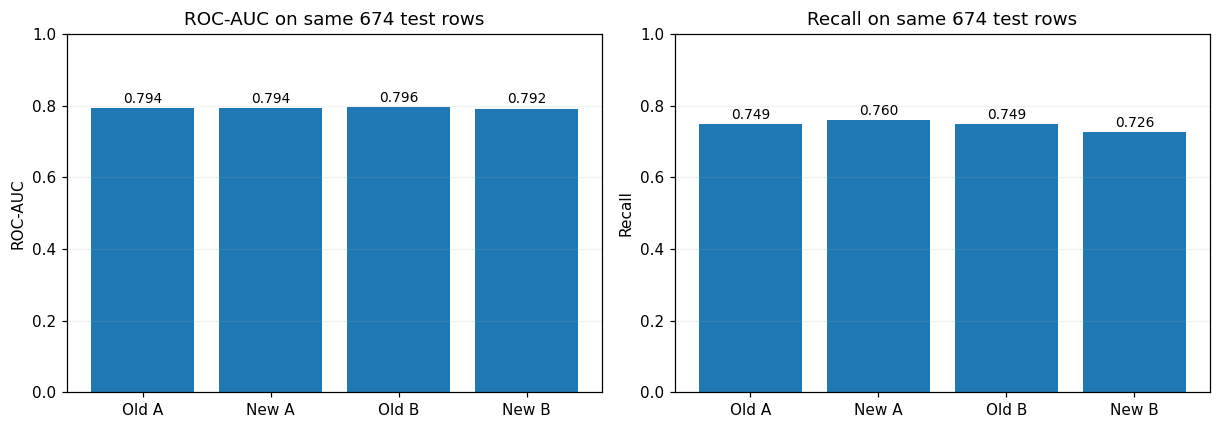

['/mnt/data/ANN_Outputs_NewData/original_data_train_only_kmeans.joblib']

In [21]:
# Match the nine Stage 2 input features for training-only K-Means.
km_old = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=SEED)
km_old.fit(X_old_tr[cluster_features])
c_old_train = km_old.predict(X_old_tr[cluster_features])
c_old_val = km_old.predict(X_old_val[cluster_features])
c_old_test = km_old.predict(X_old_test[cluster_features])
old_centres = (X_old_tr_raw.assign(_cluster=c_old_train)
               .groupby("_cluster")[["tenure", "MonthlyCharges"]].mean()
               .sort_values(["tenure", "MonthlyCharges"]))
old_cluster_map = {int(v):int(i) for i,v in enumerate(old_centres.index)}
old_map = lambda labels: np.asarray([old_cluster_map[int(z)] for z in labels],dtype=int)
c_old_train, c_old_val, c_old_test = map(old_map, [c_old_train,c_old_val,c_old_test])
X_old_b_train=with_one_hot_clusters(X_old_tr,c_old_train)
X_old_b_val=with_one_hot_clusters(X_old_val,c_old_val)
X_old_b_test=with_one_hot_clusters(X_old_test,c_old_test)

old_w = compute_class_weight(class_weight="balanced", classes=np.array([0,1]), y=y_old_tr)
old_class_weights = {0:float(old_w[0]), 1:float(old_w[1])}
def train_old_ann(Xtr, Xv, seed):
    model=build_ann(Xtr.shape[1],seed)
    history=model.fit(Xtr.to_numpy(dtype=np.float32),y_old_tr,
         validation_data=(Xv.to_numpy(dtype=np.float32), y_val),
         epochs=65, batch_size=256, verbose=0, class_weight=old_class_weights,
         callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=8,restore_best_weights=True),
                    keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.5,patience=4,min_lr=1e-5)])
    return model,history

old_a, old_hist_a = train_old_ann(X_old_tr, X_old_val, SEED)
old_b, old_hist_b = train_old_ann(X_old_b_train, X_old_b_val, SEED)
print("Old ANN A epochs:",len(old_hist_a.history["loss"]))
print("Old ANN B epochs:",len(old_hist_b.history["loss"]))

# Evaluate all FOUR ANN models on the SAME held-out customers.
old_pa=pred_prob(old_a, X_old_test)
old_pb=pred_prob(old_b, X_old_b_test)
comparison_sensitivity = pd.DataFrame([
    evaluate("Original 7,043 — ANN A (no cluster)",y_test,old_pa,.50),
    evaluate("Revised 6,741 — ANN A (no cluster)",y_test,prob_test["ANN A — No Cluster"],.50),
    evaluate("Original 7,043 — ANN B (+ cluster)",y_test,old_pb,.50),
    evaluate("Revised 6,741 — ANN B (+ cluster)",y_test,prob_test["ANN B — With Cluster"],.50),
]).set_index("Model")
print("FOUR-MODEL SENSITIVITY COMPARISON — SAME TEST CUSTOMERS (threshold 0.50):")
print(comparison_sensitivity.round(4).to_string())
comparison_sensitivity.to_csv(OUT/"ANN_Original7043_vs_Deduplicated6741_SameTest.csv")

fig,axes=plt.subplots(1,2,figsize=(11.2,4))
for ax,metric in zip(axes,["ROC-AUC","Recall"]):
    vals=comparison_sensitivity[metric]
    ax.bar(["Old A","New A","Old B","New B"],vals.values)
    ax.set(title=f"{metric} on same {len(y_test):,} test rows",ylim=(0,1),ylabel=metric)
    ax.grid(axis="y",alpha=.17)
    for j,v in enumerate(vals.values):ax.text(j,v+.015,f"{v:.3f}",ha="center",fontsize=9)
fig.tight_layout();fig.savefig(OUT/"07_old_vs_new_same_test_metrics.png",bbox_inches="tight")
plt.show()

old_a.save(OUT/"ann_original7043_a_no_cluster.keras")
old_b.save(OUT/"ann_original7043_b_with_cluster.keras")
joblib.dump(old_scaler, OUT/"original_data_train_only_scaler.joblib")
joblib.dump({"model":km_old,"cluster_map":old_cluster_map,"features":cluster_features},
            OUT/"original_data_train_only_kmeans.joblib")


## 3.19 Interpretation, conclusions and methodological boundaries

**Interpretation of the sensitivity analysis.** Compare old/new rows of the table separately for ANN A and ANN B. If the differences are small, duplicate removal has a limited observed effect **on this holdout split**. If recall or ROC-AUC shifts materially, repeated training profiles influence learning and the impact should be examined. A single 10% test set cannot establish a universal result.

**Why the source sizes are 7,043 and 6,741 but the old training count is not 7,043:** the datasets must set aside identical independent holdouts. Consequently, only copies belonging to *training profiles* are retained for original-data model fitting; copies belonging to validation/test profiles are excluded from training, and validation/test each use only one copy. That is the only way to make a leakage-free, apples-to-apples comparison.

**Is 70/20/10 better than 80/20?** Neither is categorically superior. A proper 80/20 protocol can split training internally for validation. A 70/20/10 split was adopted because a dedicated 20% validation partition supports early stopping, hyperparameter and threshold choices, while a separate untouched 10% test partition measures final generalisation. Its smaller test sample increases evaluation uncertainty; repeat group-aware validation if model selection is sensitive.

**SeniorCitizen decision:** retain the original **0/1** flag. A senior customer is a valid category, not an outlier; converting 1 to an above-average z-score cannot justify removing or down-weighting such customers. Standardisation of this flag is not inherently invalid for every ANN, but keeping 0/1 is clearer and consistent with the other indicator features.

**Business value:** Recall reflects missed churners; precision reflects unnecessary retention outreach. Use the comparison to justify the pipeline and disclose limitations, not to claim the removal of duplicates is objectively correct without identity information.


In [22]:
# Calculate effects of deduplication for each model type on the COMMON test set.
for label in ["A (no cluster)","B (+ cluster)"]:
    k="ANN A (no cluster)" if label.startswith("A") else "ANN B (+ cluster)"
    old_result=comparison_sensitivity.loc[f"Original 7,043 — {k}"]
    new_result=comparison_sensitivity.loc[f"Revised 6,741 — {k}"]
    print(f"\nANN {label}:")
    print(f"  ROC-AUC change after deduplication: {new_result['ROC-AUC']-old_result['ROC-AUC']:+.4f}")
    print(f"  Recall change after deduplication: {new_result['Recall']-old_result['Recall']:+.2%} points")
    print(f"  F1 change after deduplication: {new_result['F1-score']-old_result['F1-score']:+.2%} points")

comparison_note=(
    "Part 3 ADDITIONAL ANALYSIS – Original 7,043 vs Revised 6,741\n"
    f"Same independent test set: {len(y_test)} unique records; common validation set: {len(y_val)} records.\n"
    f"New training: {len(train_idx)} unique rows. Old training: {len(old_training_row_ids)} rows "
    f"(includes {old_repeats_in_training} retained duplicate copies from train only).\n\n"
    + comparison_sensitivity.round(4).to_string() + "\n\n"
    "The model comparison is a sensitivity check, not proof that every removed row represented "
    "the same person. Old source has 7,043 records but held-out customers (and all their "
    "copies) were excluded from training to protect test independence. "
    "70/20/10 grouped split; no test-data information enters training-only scaling or K-Means."
)
(OUT/"Old_vs_New_Comparison_Explanation.txt").write_text(comparison_note,encoding="utf-8")
print("\nSaved comparison summary and 100-pair evidence to:",OUT)



ANN A (no cluster):
  ROC-AUC change after deduplication: +0.0005
  Recall change after deduplication: +1.12% points
  F1 change after deduplication: +0.49% points

ANN B (+ cluster):
  ROC-AUC change after deduplication: -0.0034
  Recall change after deduplication: -2.23% points
  F1 change after deduplication: -0.23% points

Saved comparison summary and 100-pair evidence to: /mnt/data/ANN_Outputs_NewData
